# Let's make a light curve from PANOPTES images!

## What is a light curve?
A light curve shows how the brightness of a star changes over time.
Some stars pulsate, some are eclipsed by a companion, some have a planet passing in front of them.
In this notebook, we measure the brightness of one star on every image of an observation sequence,
and we plot it against time. The example used here is **DY Peg**, a pulsating star whose brightness
changes by about 0.6 magnitude every 1.75 hours.

## What you need
- A folder of images in `.fits.fz` format, taken by a PANOPTES unit.
- Python with the libraries imported in the next cell (see the README for installation).

## How to use this notebook
1. Fill in the **parameters** cell below (data folder, reference image, star name).
2. Run the cells **in order**, from top to bottom.
3. After each step, **look at the plot or the printed values** before moving on.
   Each section ends with a *"What can go wrong?"* note: it tells you what a bad result looks like
   and which setting to change.

## The steps
0. Parameters and imports
1. Open an image and read its header
2. Are there stars in the image?
3. Colour camera or not?
4. Detect the stars
5. Find where the image points in the sky (astrometry)
6. Find the target star
7. Measure the target's brightness (aperture photometry)
8. Choose comparison stars
9. Write a measurement function
10. Loop over all images
11. Plot the light curve and check its quality
12. Save the results

In [1]:
# --- Libraries used in this notebook ---
# Run this cell first. If you get "ModuleNotFoundError", the library is not installed (see the README).

import glob                                    # list all the files in a folder
import numpy as np                             # numerical calculations on arrays (images are 2D arrays)
import matplotlib.pyplot as plt                # plots and image display

from astropy.io import fits                    # read astronomical images (FITS format)
from astropy.coordinates import SkyCoord       # positions in the sky (right ascension, declination)
from astropy.time import Time                  # dates and times
import astropy.units as u                      # physical units (seconds, degrees...)
from astropy.table import Table                # tables of data, easy to save as CSV
from astropy.stats import sigma_clipped_stats  # statistics that ignore extreme values (stars, hot pixels)
from astropy.visualization import ZScaleInterval  # automatic contrast to display faint details

from astroquery.mast import Catalogs           # download star catalogs from the internet

from photutils.detection import DAOStarFinder  # detect stars in an image
from photutils.centroids import centroid_sources, centroid_com  # find the precise centre of a star
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats  # measure brightness

from twirl import compute_wcs                  # match image stars with catalog stars (astrometry)
from scipy.ndimage import gaussian_filter      # blur an image (used to find the brightest star robustly)

%matplotlib inline

In [ ]:
# --- Parameters: this is the only cell you need to edit ---

# Folder containing your images (.fits.fz).
# The path is relative to the location of this notebook.
DATA_FOLDER = "data/20261113T174736"

# One image of the folder used to set everything up (detection, astrometry, choice of comparison stars).
# Choose an image where the stars look round and sharp: no trails, no clouds.
# Write only the file name, not the folder.
REFERENCE_FILE = "20261113T174833.fits.fz"

# Name of your target star, as known by the SIMBAD database.
# Look it up on simbad.cds.unistra.fr and copy its main identifier.
# Examples of accepted names: "DY Peg", "DY Pegasi", "HD 218549".
TARGET_NAME = "DY Peg"

# Copy them from SIMBAD or VSX (vsx.aavso.org) if the server are down. If you change TARGET_NAME, change them too!
TARGET_COORD_BACKUP = "23h08m51.2s +17d12m56s" 

# Full path to the reference image (built automatically, do not modify)
REFERENCE_PATH = DATA_FOLDER + "/" + REFERENCE_FILE

In [ ]:
# --- Check that the star name is recognised ---
# This cell asks the SIMBAD database for the coordinates of your target.

try:
    target_coord = SkyCoord.from_name(TARGET_NAME)
    print("Coordinates found online for", TARGET_NAME)
except Exception:
    print("WARNING: online search failed. Using the backup coordinates TARGET_COORD_BACKUP.")
    target_coord = SkyCoord(TARGET_COORD_BACKUP)

# Coordinates in degrees (the format used by the code)
print("Coordinates in degrees  : RA =", target_coord.ra.deg, " Dec =", target_coord.dec.deg)

# Same coordinates in hours-minutes-seconds (the format shown on the SIMBAD website)
print("Coordinates (SIMBAD format):", target_coord.to_string("hmsdms", sep=" "))

# Compare the second line with the coordinates shown on the SIMBAD page of your star.
# If they match, you can go on.
#
# If you get an error "NameResolveError":
#   - check the spelling of TARGET_NAME on SIMBAD

Coordinates found online for DY Peg
Coordinates in degrees  : RA = 347.21327418438  Dec = 17.21555486828001
Coordinates (SIMBAD format): 23 08 51.18580425 +17 12 55.99752581


## 1. Open the reference image and read its header

Astronomical images are stored in **FITS** files. A FITS file contains two things:
- the **image**: a 2D array of numbers, one per pixel. Each number is the amount of light received by that pixel, in ADU (the camera's unit).
- the **header**: a list of keywords describing the image (date, exposure time, where the telescope was pointing...).

Our files end in `.fits.fz`, which means they are compressed. In a compressed file, the first extension (number 0) is empty: the image and its header are in **extension 1**. That is why you will see `[1]` in the code.

In [7]:
# Open the file, read the image and the header, then close the file.
# The "with" block closes the file automatically at the end.
with fits.open(REFERENCE_PATH) as hdu_list:
    hdu_list.info()                    # list the extensions of the file
    image = hdu_list[1].data           # the image (2D array of pixel values)
    header = hdu_list[1].header        # the header (keywords)

print("Image size (rows, columns):", image.shape)
print()

# Useful header keywords
print("Image type        :", header["IMAGETYP"])   # should be "Light Frame" (a sky image)
print("Exposure time (s) :", header["EXPTIME"])
print("Date (UTC)        :", header["DATE-OBS"])   # start of the exposure, in UTC
print("Field name        :", header["FIELD"])      # label typed by the operator, not always a SIMBAD name
print("Mount RA (deg)    :", header["RA-MNT"])     # where the mount thinks it is pointing
print("Mount Dec (deg)   :", header["DEC-MNT"])
print("Airmass           :", header["AIRMASS"])    # 1 = star overhead, larger = closer to the horizon
print("Latitude (deg)    :", header["LAT-OBS"])    # position of the telescope on Earth
print("Longitude (deg)   :", header["LONG-OBS"])

Filename: data/20261113T174736/20261113T174833.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   ()      
  1  COMPRESSED_IMAGE    1 CompImageHDU     40   (4144, 2822)   int16 (rescales to uint16)   


Image size (rows, columns): (2822, 4144)

Image type        : Light Frame
Exposure time (s) : 9.0
Date (UTC)        : 2026-11-13T17:48:33.416
Field name        : dy pegasis
Mount RA (deg)    : 347.55271
Mount Dec (deg)   : 17.2182
Airmass           : 1.2071637035934502
Latitude (deg)    : 46.5172
Longitude (deg)   : 6.5689


In [ ]:
# Distance on the sky between where the mount points and the target.
# The field of view is about 13 x 9 degrees, so the target should be within ~4 degrees.
mount_coord = SkyCoord(header["RA-MNT"], header["DEC-MNT"], unit="deg")
separation = mount_coord.separation(target_coord).deg

print("Distance between mount pointing and target:", round(separation, 2), "degrees")

Distance between mount pointing and target: 0.32 degrees


### What can go wrong?

**`FileNotFoundError`**
Python cannot find the file. Check `DATA_FOLDER` and `REFERENCE_FILE` in the parameters cell.
Remember that the path is relative to the folder where this notebook is saved.

**`KeyError: "Keyword '...' not found"`**
The keyword does not exist in this header. Check the spelling (`LAT-OBS` uses a hyphen, not an underscore).
Other cameras or software may use different keywords: to see all of them, run `print(list(header.keys()))`.

**The image type is not "Light Frame"**
The image is a calibration image ("Dark", "Flat", "Bias"), not a picture of the sky. Choose another file.

**The date is in UTC**
`DATE-OBS` is given in Universal Time. In Switzerland, add 1 hour in winter and 2 hours in summer
to get the local time. Images taken shortly after sunset can be too bright, or show no stars at all.
Section 2 will check this.

**The field name is not the star name**
`FIELD` is a label typed by the person who planned the observation (here `"dy pegasis"`).
It is not always a name that SIMBAD recognises: always use `TARGET_NAME` for the code.

**The distance between the mount and the target is large**
If it is more than about 4 degrees, the target may be outside the image: check that you are using the right folder.
Be careful, a small distance is not a guarantee either: the mount coordinates in the header can be
wrong by a few degrees (we found an error of about 3 degrees on this data set).
The true pointing of the image is measured in section 5 (astrometry).

## 2. Are there stars in the image?

Before doing anything else, we check that the image actually contains stars.
This sounds obvious, but an image can be useless (camera covered, roof closed, clouds, twilight)
and it is much faster to see it now than after hours of processing.

A few things to know:
- **The background is never 0.** The camera adds a constant electronic level (the *offset*),
  and the night sky itself is not perfectly dark. Without any light, our camera gives about 524 ADU;
  with a night sky, about 7000 ADU.
- **A star is a small group of pixels** clearly brighter than the background, forming a round spot
  (on these images, a small ring, because the focus is not perfect).
- **The maximum value is 65535 ADU** (16-bit camera). A star reaching this value is *saturated*:
  its brightness cannot be measured.
- **Why not just display the image?** Pixel values go from a few hundred to 65535, but almost all pixels
  are close to the background. With a simple linear display, the image looks uniformly grey.
  **ZScale** automatically chooses a contrast centred on the background, which makes faint stars visible.

In [ ]:
# Basic statistics of the image
print("Minimum value :", np.min(image))
print("Maximum value :", np.max(image))
print("Median value  :", np.median(image))

# Background level and noise.
# sigma_clipped_stats ignores extreme values (stars, hot pixels) and keeps only the background.
mean_bg, median_bg, std_bg = sigma_clipped_stats(image, sigma=3.0)
print("Background level :", median_bg, "ADU")
print("Background noise :", round(std_bg, 1), "ADU")

# Count the pixels clearly brighter than the background (10 times the noise above it).
# The threshold is relative to the background, so it works whatever the sky brightness.
threshold = median_bg + 10 * std_bg
n_bright = np.sum(image > threshold)
print("Pixels brighter than background + 10 sigma:", n_bright)

Minimum value : 5000
Maximum value : 65532
Median value  : 7160.0
Background level : 7156.0 ADU
Background noise : 635.2 ADU
Pixels brighter than background + 10 sigma: 17045


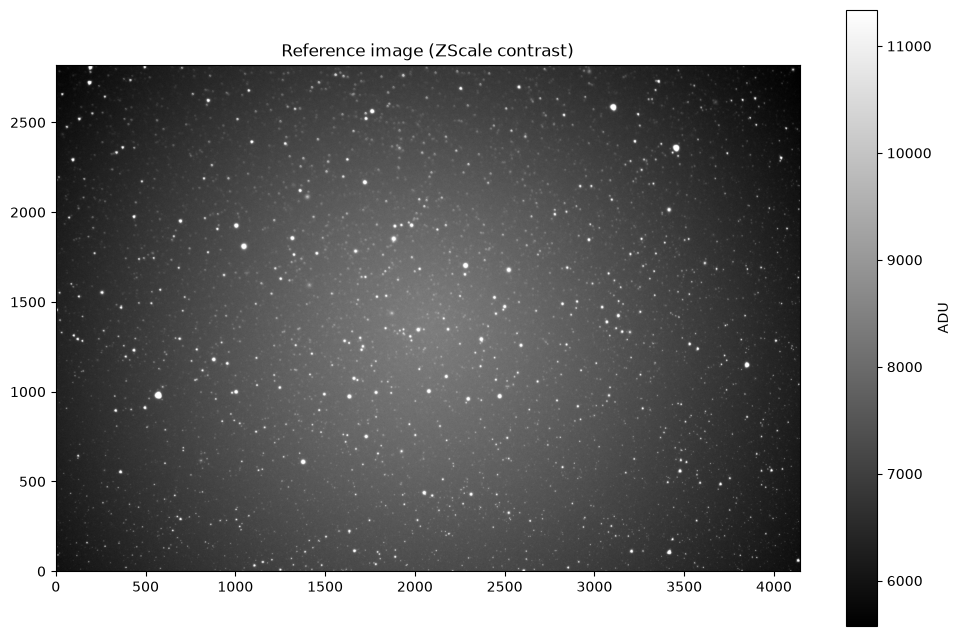

In [ ]:
# Display the whole image with an automatic contrast (ZScale)
zscale = ZScaleInterval()
vmin, vmax = zscale.get_limits(image)

plt.figure(figsize=(12, 8))
plt.imshow(image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.colorbar(label="ADU")
plt.title("Reference image (ZScale contrast)")
plt.show()


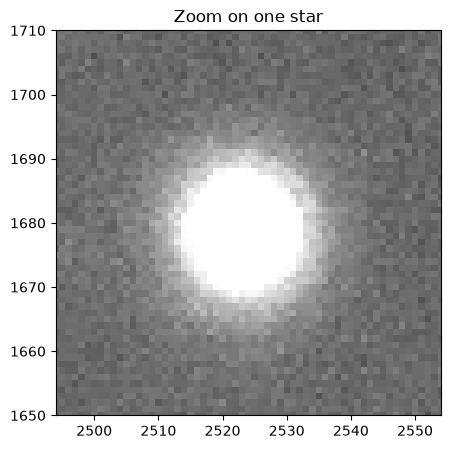

In [ ]:
# Zoom on one star to check that it covers several pixels (a hot pixel covers only one).
# Choose the position of a star by looking at the image above.
STAR_X = 2524
STAR_Y = 1680

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
plt.xlim(STAR_X - 30, STAR_X + 30)
plt.ylim(STAR_Y - 30, STAR_Y + 30)
plt.title("Zoom on one star")
plt.show()

In [ ]:
# Quick check of all the images in the folder.
# For each image we compute the background level and the number of bright pixels.
files = sorted(glob.glob(DATA_FOLDER + "/*.fits.fz"))
print("Number of images:", len(files))

medians = []
bright_counts = []

for f in files:
    data = fits.getdata(f, ext=1)

    # Statistics on 1 pixel out of 4 in each direction: much faster, and accurate enough here
    mean_f, median_f, std_f = sigma_clipped_stats(data[::4, ::4], sigma=3.0)

    medians.append(median_f)
    bright_counts.append(np.sum(data > median_f + 10 * std_f))

plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(medians, ".")
plt.ylabel("Background (ADU)")
plt.title("Background level of each image")

plt.subplot(2, 1, 2)
plt.plot(bright_counts, ".")
plt.xlabel("Image number")
plt.ylabel("Bright pixels")
plt.title("Number of bright pixels in each image")

plt.tight_layout()
plt.show()

#This cell might take a moment to run, it's completely normal as it goes throught all the fits file of the folder
#If you didn't load the whole files, this graph will only show one point, completely normal :)

Number of images: 476


#### How to read these two plots 

**What you should expect with good data:**
   - The background slowly goes down during the night: the sky gets darker after twilight,
    and the star rises higher in the sky, away from the light pollution near the horizon.
   - The number of bright pixels slowly goes up: with a darker background, the threshold is lower,
    so more pixels of faint stars pass it. Stars higher in the sky also look a bit brighter.
   Slow trends like these are normal and do not affect the measurements.

**What deserves a closer look:**
   - A sudden step in the background (up for a few images, then back down):
     a thin cloud lit by the city, or the mount changing its pointing.
   - A single image with many more bright pixels than its neighbours:
     usually a plane or satellite trail crossing the image, or stars stretched into lines
     because the mount moved during the exposure.
   - A sudden drop in the number of bright pixels: clouds hiding the stars.
   - Almost no bright pixels in all images: there are no stars in this data set (see section 2).

 To look at a suspicious image, find its number on the plot and display it:
   suspicious_image = fits.getdata(files[NUMBER], ext=1)
 then show it with the same code as the ZScale display above.

### What can go wrong?

**Uniform noise with horizontal stripes, no stars, background around 524 ADU**
No light reaches the sensor: the lens is covered or the roof is closed. The images are unusable.
This is what we got with our first data set.

**White dots everywhere, but each one is a single pixel in the zoom**
These are hot pixels (defective pixels that always look bright) and noise, not stars.
This is a classic trap when the contrast is very tight: noise can look like a field of stars.

**Very bright background, or a strong gradient across the image**
Twilight, the Moon or light pollution. Faint stars are lost in the background.
Note: a background slightly brighter in the centre than in the corners is normal (vignetting of the lens).

**Stars stretched into short lines**
The mount moved during the exposure. Choose another reference image with round stars.

**Stars shaped like small rings**
The focus is not perfect. This is not a problem, but the measurement circle will need to be larger (section 7).

**On the folder check: the background goes up, or the number of bright pixels drops**
Clouds, twilight or the end of the night. The images concerned will give less reliable measurements.
If the number of bright pixels is almost zero for all images, there are no stars in this data set.

## 3. Colour camera or not?

Many cameras used by PANOPTES are **colour cameras**. Their sensor is covered by a grid of tiny
colour filters called a **Bayer matrix**: in each block of 2 x 2 pixels, one pixel sees red,
two pixels see green, and one pixel sees blue (pattern "RGGB").

This matters for photometry. If we simply add up all the pixels of a star, we mix three colours
that the camera does not see with the same sensitivity. The result then depends on the colour of
the star and on how its light falls on the grid. To avoid this, on a colour camera we keep
**only the green pixels** (one pixel out of four, or one out of two in each direction).

Be careful: the header keyword `FILTER` may say "RGGB" even when the camera is not a colour camera.
We do not trust it, we **test** it.

**The test:** we measure one star in the 4 sub-grids of pixels (even/odd rows, even/odd columns).
- On a colour camera, the two green sub-grids are on a **diagonal** and give almost the same value,
  while the other two (red and blue) are clearly different.
- On a monochrome camera, the **four values are almost equal**.

Note: comparing the background of the 4 sub-grids is not enough. The background is mostly the
electronic offset of the camera, which is the same for all pixels. We need the light of a star.

In [ ]:
# Choose a star that is bright but NOT saturated (you can reuse the one from the zoom in section 2).
# Both coordinates must be EVEN numbers: the box must start on an even row and an even column,
# so that its 4 sub-grids correspond to the 4 sub-grids of the whole image.
TEST_X = 2524
TEST_Y = 1680

# Cut a box of 40 x 40 pixels around the star
box = image[TEST_Y - 20 : TEST_Y + 20, TEST_X - 20 : TEST_X + 20].astype(float)

# Check that the star is not saturated (maximum possible value: 65535)
print("Maximum value in the box:", np.max(box))
if np.max(box) > 60000:
    print("WARNING: the star is probably saturated, choose a fainter one.")

# Remove the background (median of the box)
box = box - np.median(box)

# Sum of the star light in each of the 4 sub-grids
# [row start::2, column start::2]
sum_00 = np.sum(box[0::2, 0::2])   # even rows, even columns
sum_01 = np.sum(box[0::2, 1::2])   # even rows, odd columns
sum_10 = np.sum(box[1::2, 0::2])   # odd rows, even columns
sum_11 = np.sum(box[1::2, 1::2])   # odd rows, odd columns

print("Sum 00:", round(sum_00))
print("Sum 01:", round(sum_01))
print("Sum 10:", round(sum_10))
print("Sum 11:", round(sum_11))

Maximum value in the box: 33652.0
Sum 00: 539864
Sum 01: 527600
Sum 10: 516660
Sum 11: 522216


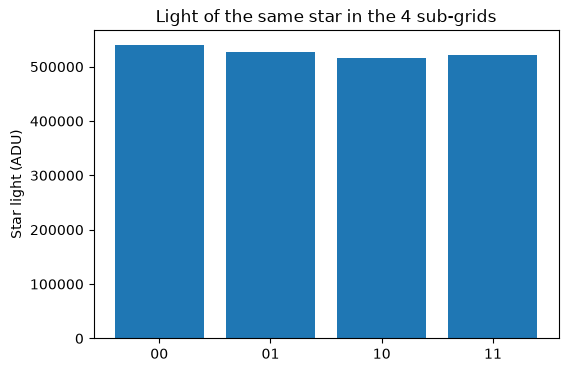

Spread between the 4 sub-grids: 4.4 %
The 4 values are almost equal: the camera is probably MONOCHROME.


In [ ]:
# Bar chart of the 4 sums
sums = [sum_00, sum_01, sum_10, sum_11]
labels = ["00", "01", "10", "11"]

plt.figure(figsize=(6, 4))
plt.bar(labels, sums)
plt.ylabel("Star light (ADU)")
plt.title("Light of the same star in the 4 sub-grids")
plt.show()

# Relative spread between the 4 values: (largest - smallest) / mean
spread = (max(sums) - min(sums)) / np.mean(sums)
print("Spread between the 4 sub-grids:", round(100 * spread, 1), "%")

# Compare the two diagonals: the green pair is the one whose two values are the closest
diff_diag_a = abs(sum_00 - sum_11) / np.mean(sums)   # diagonal 00 / 11
diff_diag_b = abs(sum_01 - sum_10) / np.mean(sums)   # diagonal 01 / 10

if spread < 0.10:
    print("The 4 values are almost equal: the camera is probably MONOCHROME.")
elif diff_diag_a < diff_diag_b:
    print("Diagonal 00 / 11 matches: probably a COLOUR camera, green pixels in [0::2, 0::2] and [1::2, 1::2].")
else:
    print("Diagonal 01 / 10 matches: probably a COLOUR camera, green pixels in [0::2, 1::2] and [1::2, 0::2].")

In [ ]:
# Write here the conclusion of the test above.
COLOUR_CAMERA = False

if COLOUR_CAMERA:
    # Keep only one green sub-grid. Replace [0::2, 1::2] by the green sub-grid found above.
    # The image becomes 2 times smaller in each direction.
    # IMPORTANT: the same slicing must be applied to every image in the loop (section 10).
    science_image = image[0::2, 1::2]
else:
    # Monochrome camera: we keep the full image
    science_image = image

print("Image used for the measurements:", science_image.shape)

Image used for the measurements: (2822, 4144)


### What can go wrong?

**The maximum value in the box is above 60000**
The star is saturated: all its brightest pixels are stuck at the same maximum value, in all colours.
The 4 sums then look equal even on a colour camera. Choose a fainter star.

**The 4 sums are very different but no diagonal pair matches**
The star is probably too faint (the noise dominates) or another star falls in the box.
Choose a brighter, isolated star.

**The coordinates are odd numbers**
The box starts on an odd row or column, so "00" in the box is not "00" in the image.
The test still shows a matching diagonal, but you would keep the wrong pixels. Always use even coordinates.

**The header says "RGGB" but the test says monochrome**
This is what happens with our data. Trust the test, not the header.

**Good practice**
Repeat the test on 2 or 3 different stars. The conclusion must be the same each time.

## 4. Detect the stars

To know which part of the sky the image shows (section 5), we need the positions of the
brightest stars in the image. We find them automatically with **DAOStarFinder** (photutils).

DAOStarFinder looks for small bright spots of a given size. It needs two settings:
- **FWHM** (*Full Width at Half Maximum*): the typical width of a star, in pixels.
  It is the width of the star's light profile measured at half of its peak value.
- **Threshold**: how much brighter than the background a spot must be to count as a star,
  in units of the background noise (for example 5 means "5 times the noise above the background").

The result is a table with one line per star: its position (`x_centroid`, `y_centroid`),
its brightest pixel (`peak`) and an estimate of its total light (`flux`).
We sort this table from the brightest to the faintest star.

The values below work for a PANOPTES unit with this focus. The visual check at the end of the
section tells you if you need to change them.

In [ ]:
# --- Settings for this section ---
FWHM = 4                   # typical width of a star in pixels (look at the zoom of section 2)
DETECTION_THRESHOLD = 5    # a star must be this many times the noise above the background
N_BRIGHTEST = 15           # number of bright stars kept for the astrometry (section 5)

# Background level and noise of the image (extreme values ignored)
mean_bg, median_bg, std_bg = sigma_clipped_stats(science_image, sigma=3.0)

# Detect the stars on the image minus its background
finder = DAOStarFinder(fwhm=FWHM, threshold=DETECTION_THRESHOLD * std_bg)
stars = finder.find_stars(science_image - median_bg)
print("Number of detected stars:", len(stars))

# Sort from the brightest to the faintest
stars.sort("flux", reverse=True)

# Show the brightest ones.
# Note: in older versions of photutils, the columns are called "xcentroid" and "ycentroid".
print(stars["x_centroid", "y_centroid", "peak", "flux"][0:10])

# Positions (x, y) of the brightest stars, as an array of N lines and 2 columns.
# They will be used in section 5.
positions = np.column_stack((stars["x_centroid"], stars["y_centroid"]))[0:N_BRIGHTEST]

NameError: name 'science_image' is not defined

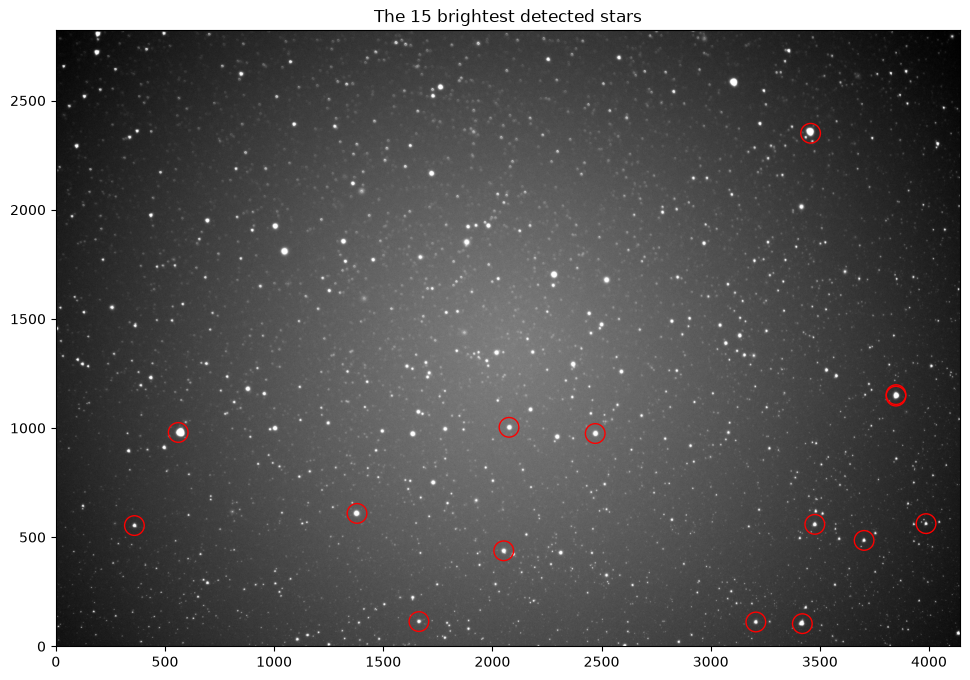

Pairs of detections too close to each other: 1


In [ ]:
# Display the image with a red circle on each of the brightest stars
zscale = ZScaleInterval()
vmin, vmax = zscale.get_limits(science_image)

plt.figure(figsize=(12, 8))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(positions[:, 0], positions[:, 1], s=200, edgecolor="red", facecolor="none")
plt.title("The " + str(N_BRIGHTEST) + " brightest detected stars")
plt.show()

# Count the pairs of detections that are too close to each other:
# two detections closer than 3 x FWHM are probably the same star counted twice.
n_close = 0
for i in range(len(positions)):
    for j in range(i + 1, len(positions)):
        dx = positions[i, 0] - positions[j, 0]
        dy = positions[i, 1] - positions[j, 1]
        distance = np.sqrt(dx**2 + dy**2)
        if distance < 3 * FWHM:
            n_close += 1

print("Pairs of detections too close to each other:", n_close)

### What can go wrong?

**Double circles, or "pairs too close" above 0**
The same star is detected several times. This happens with bright saturated stars:
their top is flat and wide, and a too small FWHM sees several small peaks in it.
Increase `FWHM`. (With FWHM = 1.5 on this data, we got about 10 different stars out of 15.)

**Some of the brightest stars of the image have no circle**
They are probably saturated and rejected because their shape does not look like the expected spot.
Increase `FWHM`.

**Circles on empty sky, or on single bright pixels**
Hot pixels or noise are detected as stars. Increase `DETECTION_THRESHOLD` or `FWHM`.

**Very few stars detected**
The threshold is too high, or the image has a problem (go back to section 2).

**The circles are not exactly on the brightest stars**
This is normal: saturated stars all reach the same maximum value, so their order in the list
is not perfect. What matters is that the circles are on real, distinct, bright stars.

## 5. Find where the image points in the sky (astrometry)

So far we know the positions of stars **in pixels**. To find our target, we need to know which pixel
corresponds to which position **in the sky** (right ascension, declination).
This correspondence is called the **WCS** (*World Coordinate System*), and finding it is called
**astrometry** or *plate solving*.

How it works:
1. We download a **catalog** of the bright stars around the pointing of the mount
   (here the TIC catalog, from the MAST archive).
2. **twirl** compares the patterns drawn by the brightest stars of the image with the patterns
   drawn by the brightest stars of the catalog (like recognising a constellation), and finds
   the transformation between the two.

Two checks tell us if the result is correct:
- the **pixel scale** (how many degrees of sky one pixel covers) must match what we expect
  from the camera and the lens;
- the catalog stars, drawn on the image, must fall **exactly on real stars**.

Remember: the mount coordinates in the header can be wrong by a few degrees.
The WCS gives the true pointing.

In [ ]:
# --- Settings for this section ---
CATALOG_RADIUS = 6     # radius (degrees) of the sky region downloaded around the mount pointing
CATALOG_MAG_MAX = 10   # faintest magnitude downloaded (TESS magnitude, larger = fainter)
N_CATALOG = 40         # number of bright catalog stars given to twirl

# Download the catalog around the mount pointing (mount_coord comes from section 1).
# This needs an internet connection and can take a few seconds.
# If you get a connection error, the server is probably busy: wait a bit and run the cell again.
catalog = Catalogs.query_criteria(coordinates=mount_coord, radius=str(CATALOG_RADIUS) + "deg",
                                  catalog="Tic", Tmag=[-2, CATALOG_MAG_MAX])
print("Number of catalog stars:", len(catalog))

# Sort from the brightest to the faintest
catalog.sort("Tmag")

# Convert the catalog columns into plain numpy arrays of numbers.
# (The table columns are "masked columns", which some numpy functions cannot handle directly.)
cat_ra = np.array(catalog["ra"], dtype=float)
cat_dec = np.array(catalog["dec"], dtype=float)

# Sky positions (RA, Dec) of the brightest catalog stars, as an array of N lines and 2 columns
radecs = np.column_stack((cat_ra, cat_dec))[0:N_CATALOG]

Number of catalog stars: 1380


In [ ]:
# --- Settings for this section ---
FOCAL_LENGTH_MM = 85   # focal length of the lens in mm (85 mm for a standard PANOPTES unit)

# Match the image stars (section 4) with the catalog stars
wcs = compute_wcs(positions, radecs)
print(wcs)

# Pixel scale measured by the WCS (degrees per pixel).
# The CD matrix contains the scale and the rotation of the image.
cd = wcs.wcs.cd
scale_measured = np.sqrt(cd[0, 0]**2 + cd[1, 0]**2)

# Pixel scale expected from the camera and the lens:
# scale (arcsec/pixel) = 206265 x pixel size / focal length
pixel_size_mm = header["XPIXSZ"] / 1000          # pixel size in the header is in micrometres
scale_expected = 206265 * pixel_size_mm / FOCAL_LENGTH_MM / 3600   # converted to degrees
if COLOUR_CAMERA:
    scale_expected = 2 * scale_expected          # one pixel out of two is kept in each direction

print("Measured pixel scale:", round(scale_measured * 3600, 2), "arcsec/pixel")
print("Expected pixel scale:", round(scale_expected * 3600, 2), "arcsec/pixel")
print("Ratio measured / expected:", round(scale_measured / scale_expected, 3))

# True pointing: sky position of the centre of the image, compared with the mount pointing
centre = wcs.pixel_to_world(science_image.shape[1] / 2, science_image.shape[0] / 2)
print("Distance between image centre and mount pointing:",
      round(centre.separation(mount_coord).deg, 2), "degrees")

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 347.8281491306254 17.78695875456851
CRPIX : 1442.4130153406124 570.9341881998616
CD1_1 CD1_2  : 0.0003527836472320861 -0.003109316176986784
CD2_1 CD2_2  : 0.0031060893877712715 0.0003718115645408779
NAXIS : 2471  1004
Measured pixel scale: 11.25 arcsec/pixel
Expected pixel scale: 11.24 arcsec/pixel
Ratio measured / expected: 1.002
Distance between image centre and mount pointing: 3.55 degrees


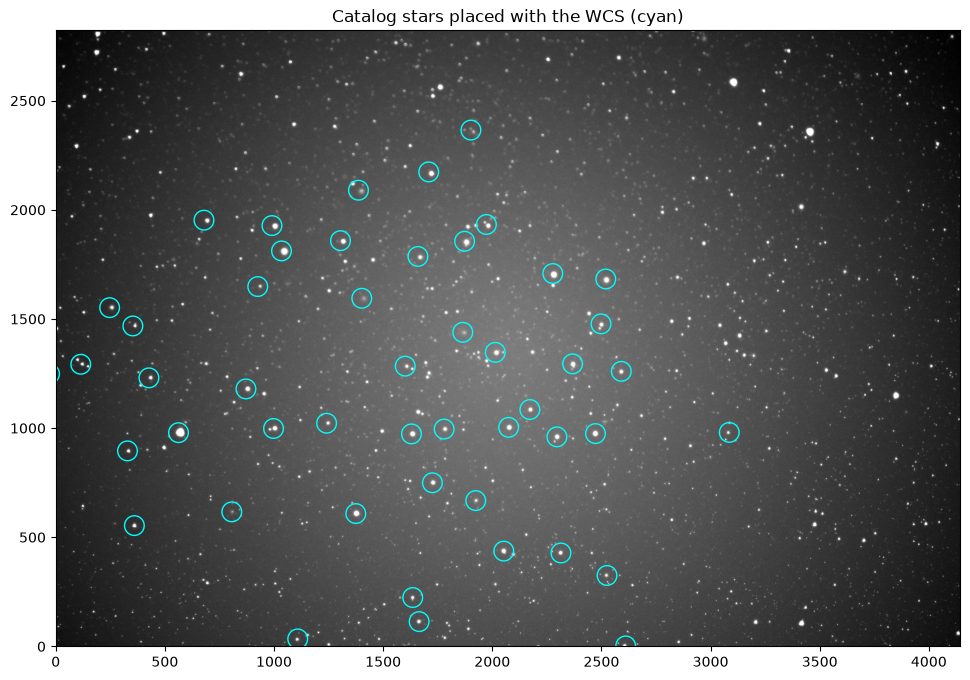

In [ ]:
# Draw the catalog stars (cyan) on the image, using the WCS to convert their sky positions to pixels
x_cat, y_cat = wcs.world_to_pixel_values(cat_ra[0:60], cat_dec[0:60])

plt.figure(figsize=(12, 8))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_cat, y_cat, s=200, edgecolor="cyan", facecolor="none")
plt.xlim(0, science_image.shape[1])     # keep only the image area
plt.ylim(0, science_image.shape[0])
plt.title("Catalog stars placed with the WCS (cyan)")
plt.show()

### What can go wrong?

**The ratio measured / expected is far from 1 (for example 30)**
twirl matched the wrong stars together, and the WCS is wrong. This happened to us when the same
star was detected several times (section 4). Check the detections, then try changing
`N_BRIGHTEST` (section 4) or `N_CATALOG` (for example 10 to 20 image stars, 30 to 60 catalog stars).

**The ratio is close to 1 but the cyan circles are next to the stars**
The scale is right but the position is slightly off. Check that you used the right reference image.
A shift of 1 or 2 pixels is normal and will be corrected later by the centroid (section 6).

**Cyan circles only on one part of the image**
The catalog was downloaded around the mount pointing, which can be wrong by a few degrees.
The part of the image far from this pointing is outside the downloaded region.
This does not matter as long as your target is in the covered part; otherwise increase `CATALOG_RADIUS`.

**Connection error (for example `ConnectionResetError`)**
The catalog server did not answer. This is not a problem with your code: wait and run the cell again.

**The ratio is close to 1 but nothing matches at all**
Check `FOCAL_LENGTH_MM`: if your lens is not 85 mm, the expected scale is wrong.

## 6. Find the target star

With the WCS, we can convert the sky position of the target (from SIMBAD) into a pixel position.
But the WCS is not perfect: the predicted position can be wrong by a few pixels.
For photometry, we need the centre of the star to better than one pixel.

We refine the position with a **centroid**: inside a small box around the predicted position,
we compute the "centre of mass" of the light, the same way you would compute the centre of mass
of an object, with the pixel values as masses.

Two details matter:
- **Background**: we first remove the local background around the star. Otherwise the background,
  which fills the whole box, pulls the centre towards the middle of the box.
  We use a *local* background because it is not the same everywhere in the image (vignetting).
- **Iterations**: if the box is not well centred at the start, it cuts part of the star and the
  centre is wrong. So we repeat the centroid, starting each time from the new position,
  until the position stops moving.

The box must be large enough to contain the whole star, but small enough not to include a neighbour.

In [ ]:
# --- Settings for this section ---
CENTROID_BOX = 11      # size (pixels) of the box used for the centroid; odd number
N_ITERATIONS = 4       # number of times the centroid is repeated

# Predicted position of the target in the image, from its sky coordinates and the WCS
x_wcs, y_wcs = wcs.world_to_pixel(target_coord)
x_wcs = float(x_wcs)
y_wcs = float(y_wcs)
print("Position predicted by the WCS: x =", round(x_wcs, 1), " y =", round(y_wcs, 1))

# Local background: median of a 60 x 60 pixel region around the target
local_bg = np.median(science_image[int(y_wcs) - 30 : int(y_wcs) + 30, int(x_wcs) - 30 : int(x_wcs) + 30])
print("Local background:", local_bg, "ADU")

# Repeat the centroid, starting each time from the last position found
x_target = x_wcs
y_target = y_wcs

for i in range(N_ITERATIONS):
    xc, yc = centroid_sources(science_image - local_bg, x_target, y_target,
                              box_size=CENTROID_BOX, centroid_func=centroid_com)
    shift = np.sqrt((xc[0] - x_target)**2 + (yc[0] - y_target)**2)   # how much the position moved
    x_target = xc[0]
    y_target = yc[0]
    print("Iteration", i + 1, ": x =", round(x_target, 2), " y =", round(y_target, 2),
          " moved by", round(shift, 2), "pixels")

Position predicted by the WCS: x = 1237.9  y = 735.8
Local background: 7644.0 ADU
Iteration 1 : x = 1240.06  y = 736.06  moved by 2.18 pixels
Iteration 2 : x = 1241.18  y = 736.14  moved by 1.13 pixels
Iteration 3 : x = 1241.52  y = 736.16  moved by 0.34 pixels
Iteration 4 : x = 1241.82  y = 736.18  moved by 0.29 pixels


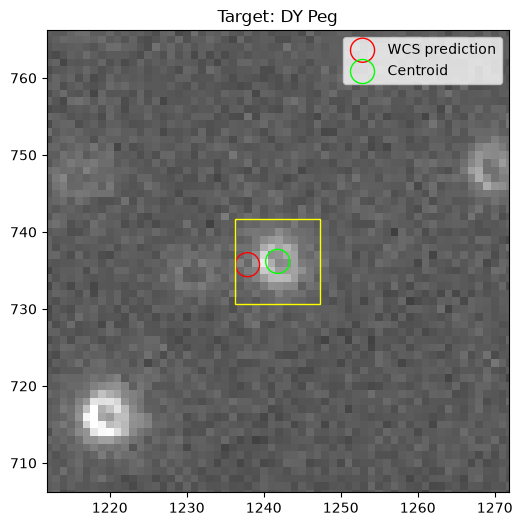

In [ ]:
# Zoom on the target: red = position predicted by the WCS, green = final centroid,
# yellow square = the centroid box at the final position
from matplotlib.patches import Rectangle

plt.figure(figsize=(6, 6))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
plt.scatter(x_wcs, y_wcs, s=300, edgecolor="red", facecolor="none", label="WCS prediction")
plt.scatter(x_target, y_target, s=300, edgecolor="lime", facecolor="none", label="Centroid")

half = CENTROID_BOX / 2
plt.gca().add_patch(Rectangle((x_target - half, y_target - half), CENTROID_BOX, CENTROID_BOX,
                              edgecolor="yellow", facecolor="none"))

plt.xlim(x_target - 30, x_target + 30)
plt.ylim(y_target - 30, y_target + 30)
plt.legend()
plt.title("Target: " + TARGET_NAME)
plt.show()

### What can go wrong?

**The red circle is a few pixels away from the star**
This is normal: the WCS is not perfectly precise. The green circle (centroid) should be on the star.

**The green circle is on the edge of the star, not in its centre**
The box cut part of the star at the start. Increase `N_ITERATIONS`, or check that `CENTROID_BOX`
is larger than the star.

**The green circle jumped to another star**
A neighbouring star is inside the box. Reduce `CENTROID_BOX` (but keep it larger than the star).

**The position keeps moving by more than ~0.5 pixel at the last iteration**
The star is too faint compared to the noise, or two stars are mixed in the box.

**No star at all near the red circle**
Check the target name (section 0), that the star is bright enough to be visible in this exposure,
and that the WCS is correct (section 5).

**Error about positions outside the data, or a predicted position with negative values**
The target is outside the image: wrong data folder, or the mount pointed elsewhere.

## 7. Measure the brightness of the target (aperture photometry)

To measure how much light a star sends us, we add up the pixel values inside a circle around it
(the **aperture**). But these pixels also contain background light, so we estimate the background
in a ring around the star (the **annulus**) and remove it:

$$F_\star = S_\text{aperture} - b \times A_\text{aperture}$$

where $S$ is the sum of the pixels in the aperture, $b$ the background per pixel (the *median* of the
annulus, which is not disturbed by a few bright pixels) and $A$ the area of the aperture in pixels.

**How to choose the radius of the aperture?** We look at two curves.

The **curve of growth** shows the flux for larger and larger radii. Ideally it reaches a plateau when the
whole star is inside the circle. In practice it often keeps increasing slowly: stars have faint, wide
wings (imperfect focus, light scattered in the lens), and neighbouring stars enter the circle.
This is not a problem: we do not need *all* the light of the star. In differential photometry, the
target and the comparison stars are measured with the same radius, so they lose the same fraction
of their light, and this fraction cancels in the ratio.

The **signal-to-noise curve** is the one that decides. A larger circle adds a bit of signal but also
more background noise. The best radius is around the maximum of this curve, or slightly larger:
a slightly larger circle is less sensitive to small errors on the position of the star.

**How precise is the measurement?** A simple estimate of the noise on the flux is
$\sigma_F \approx \sigma_\text{bg}\sqrt{A}$, where $\sigma_\text{bg}$ is the noise per pixel in the annulus.
The signal-to-noise ratio $\text{SNR} = F_\star / \sigma_F$ gives the error in magnitude:
$\sigma_m \approx 1.086 / \text{SNR}$. (This estimate ignores some other noise sources, so the
real error is a bit larger.)

Keep in mind that this curve is computed on a single image, with a perfectly centred star.
Over a whole sequence, small position errors, stretched stars or changes of focus are less harmful
with a slightly larger circle. Make sure the circle contains the whole star (look at the zoom).
The final judge is the control curve of section 11: you can run the loop with two different radii
and keep the one that gives the smallest scatter.

Background per pixel: 7608.0 ADU   Noise per pixel: 188.5 ADU


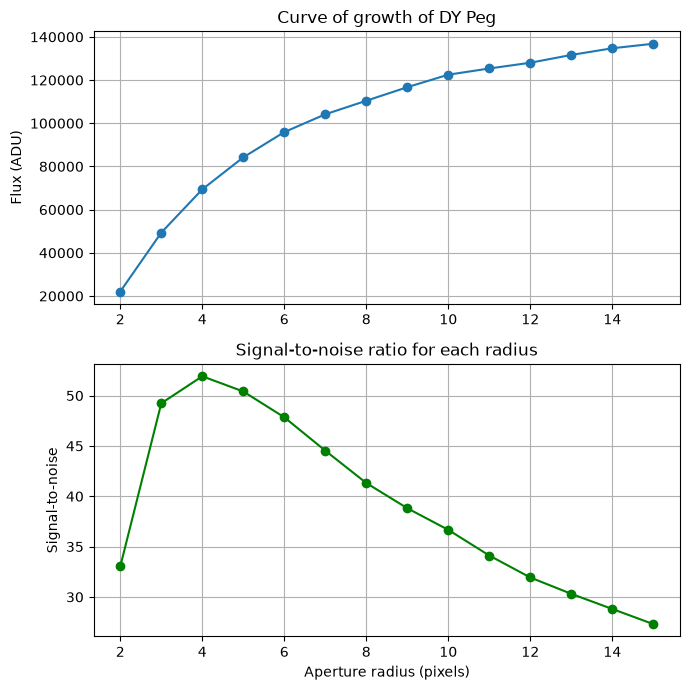

Radius with the best signal-to-noise: 4 pixels


In [ ]:
# --- Settings for this section ---
ANNULUS_IN = 16    # inner radius of the background ring (pixels): must be outside the star
ANNULUS_OUT = 22   # outer radius of the background ring (pixels)

# Background per pixel and noise per pixel, measured in the annulus around the target
annulus = CircularAnnulus((x_target, y_target), r_in=ANNULUS_IN, r_out=ANNULUS_OUT)
annulus_stats = ApertureStats(science_image, annulus)
bg_per_pixel = annulus_stats.median
bg_noise = annulus_stats.std
print("Background per pixel:", bg_per_pixel, "ADU   Noise per pixel:", round(bg_noise, 1), "ADU")

# Curve of growth: flux of the star for apertures of radius 2 to 15 pixels
radii = list(range(2, 16))
fluxes = []

snrs = []

for r in radii:
    aperture = CircularAperture((x_target, y_target), r=r)
    phot = aperture_photometry(science_image, aperture)
    flux = phot["aperture_sum"][0] - bg_per_pixel * aperture.area
    fluxes.append(flux)
    snrs.append(flux / (bg_noise * np.sqrt(aperture.area)))   # signal-to-noise for this radius

plt.figure(figsize=(7, 7))

plt.subplot(2, 1, 1)
plt.plot(radii, fluxes, "o-")
plt.ylabel("Flux (ADU)")
plt.title("Curve of growth of " + TARGET_NAME)
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(radii, snrs, "o-", color="green")
plt.xlabel("Aperture radius (pixels)")
plt.ylabel("Signal-to-noise")
plt.title("Signal-to-noise ratio for each radius")
plt.grid()

plt.tight_layout()
plt.show()

print("Radius with the best signal-to-noise on this image:", radii[np.argmax(snrs)], "pixels")
print("Recommended: this value or 1-2 pixels more, so that the whole star stays inside the circle.")

In [ ]:
# Radius chosen by looking at the curve of growth (beginning of the plateau)
APERTURE_RADIUS = 6

aperture = CircularAperture((x_target, y_target), r=APERTURE_RADIUS)
phot = aperture_photometry(science_image, aperture)
flux_target = phot["aperture_sum"][0] - bg_per_pixel * aperture.area

# Brightest pixel in the aperture: if it reaches ~65535, the star is saturated
peak = ApertureStats(science_image, aperture).max
print("Brightest pixel in the aperture:", peak, "ADU")
if peak > 60000:
    print("WARNING: the star is saturated, its flux cannot be measured correctly.")

# Noise, signal-to-noise ratio and error in magnitude
flux_noise = bg_noise * np.sqrt(aperture.area)
snr = flux_target / flux_noise
mag_error = 1.086 / snr

print("Flux of the target:", round(flux_target), "ADU")
print("Noise on the flux :", round(flux_noise), "ADU")
print("Signal-to-noise   :", round(snr, 1))
print("Error in magnitude:", round(mag_error, 3), "mag")

Brightest pixel in the aperture: 10948.0 ADU
Flux of the target: 95912 ADU
Noise on the flux : 2005 ADU
Signal-to-noise   : 47.8
Error in magnitude: 0.023 mag


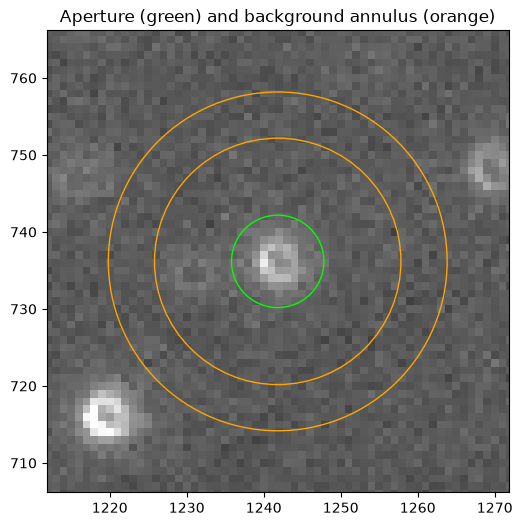

In [ ]:
# Zoom on the target with the aperture (green) and the background annulus (orange)
plt.figure(figsize=(6, 6))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
aperture.plot(color="lime")
annulus.plot(color="orange")
plt.xlim(x_target - ANNULUS_OUT - 8, x_target + ANNULUS_OUT + 8)
plt.ylim(y_target - ANNULUS_OUT - 8, y_target + ANNULUS_OUT + 8)
plt.title("Aperture (green) and background annulus (orange)")
plt.show()

### What can go wrong?

**The curve of growth never flattens and keeps increasing**
The background is underestimated, or a neighbouring star enters the aperture as the radius grows.
Look at the zoom: is there another star close to the target?

**The curve of growth never flattens and keeps increasing slowly**
This is common (faint wings of the star, neighbouring stars) and not a problem: use the
signal-to-noise curve to choose the radius. If the flux increases *fast* at large radii, look at the
zoom: a neighbouring star is probably entering the aperture.

**The curve reaches a plateau, then increases again**
A neighbouring star enters the aperture at larger radii. Choose the radius at the beginning of the
first plateau.

**The curve decreases at large radii**
The background is overestimated, often because a star falls in the annulus.
Move the annulus (`ANNULUS_IN`, `ANNULUS_OUT`) to a region without stars.

**A star is inside the orange annulus**
The median limits the damage, but it is better to move the annulus away from it.

**The brightest pixel is above 60000**
The target is saturated: its flux cannot be measured. Use shorter exposures or another target.

**Negative flux, or signal-to-noise below about 10**
There is no star at this position (check section 6), or the target is too faint for this exposure.

## 8. Choose comparison stars

The flux we measured depends on the star, but also on the atmosphere: thin clouds, haze, or the
star getting lower in the sky all reduce the light we receive. To remove these effects, we compare
the target with **comparison stars** in the same image. The atmosphere affects all of them in the
same way, so the **ratio** between the target and the comparison stars only shows the real changes
of the target.

A good comparison star is:
- **of similar brightness** to the target (same signal-to-noise, same behaviour of the camera);
- **not saturated**;
- **isolated**: no other star inside its aperture or its background annulus;
- **close to the target** in the image (same atmosphere, same part of the lens);
- **not variable** itself. We cannot know this in advance: the control curve of section 11 will tell us.

We use 3 to 5 comparison stars. The catalog downloaded in section 5 is reused: no new download needed.

Target found in the catalog 320.2 arcsec away, magnitude 9.36
Number of candidates in the whole catalog: 726


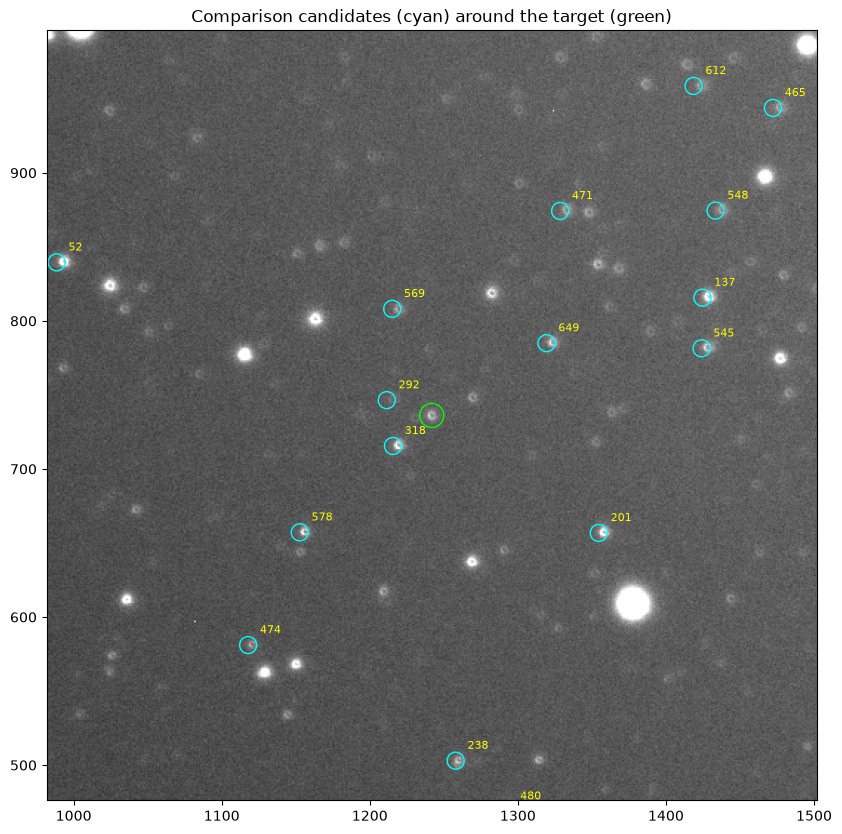

In [ ]:
# --- Settings for this section ---
COMP_MAG_RANGE = 0.5     # comparison stars must be within +/- this magnitude of the target
ZOOM_HALF_SIZE = 260     # half size (pixels) of the region shown around the target

# Find the target in the catalog: the catalog star closest to the target position
catalog_coords = SkyCoord(cat_ra, cat_dec, unit="deg")
separations = catalog_coords.separation(target_coord).arcsec
i_target = np.argmin(separations)
target_mag = catalog["Tmag"][i_target]
print("Target found in the catalog", round(separations[i_target], 1), "arcsec away, magnitude", round(target_mag, 2))

# Keep the catalog stars of similar magnitude, except the target itself
mag = np.array(catalog["Tmag"], dtype=float)
is_candidate = (abs(mag - target_mag) < COMP_MAG_RANGE) & (separations > 10)

cand_ra = cat_ra[is_candidate]
cand_dec = cat_dec[is_candidate]
cand_mag = mag[is_candidate]
print("Number of candidates in the whole catalog:", len(cand_ra))

# Pixel positions of the candidates in the image
x_cand, y_cand = wcs.world_to_pixel_values(cand_ra, cand_dec)

# Show the candidates around the target, each one with its number
plt.figure(figsize=(10, 10))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")
plt.scatter(x_cand, y_cand, s=150, edgecolor="cyan", facecolor="none")
for i in range(len(x_cand)):
    # clip_on=True hides the numbers outside the displayed region
    plt.text(x_cand[i] + 8, y_cand[i] + 8, str(i), color="yellow", fontsize=8, clip_on=True)
plt.scatter(x_target, y_target, s=300, edgecolor="lime", facecolor="none")
plt.xlim(x_target - ZOOM_HALF_SIZE, x_target + ZOOM_HALF_SIZE)
plt.ylim(y_target - ZOOM_HALF_SIZE, y_target + ZOOM_HALF_SIZE)
plt.title("Comparison candidates (cyan) around the target (green)")
plt.show()

In [ ]:
# Numbers of the chosen comparison stars, read on the image above.
# Choose 3 to 5 stars: well centred in their cyan circle, isolated, not on the edge.
COMP_INDICES = [318, 569, 649, 545, 238]

comp_x = []
comp_y = []

for i in COMP_INDICES:
    # Start from the catalog position, then refine with the centroid (same method as section 6)
    xc = x_cand[i]
    yc = y_cand[i]
    bg = np.median(science_image[int(yc) - 30 : int(yc) + 30, int(xc) - 30 : int(xc) + 30])
    for k in range(N_ITERATIONS):
        xs, ys = centroid_sources(science_image - bg, xc, yc, box_size=CENTROID_BOX, centroid_func=centroid_com)
        xc = xs[0]
        yc = ys[0]
    comp_x.append(xc)
    comp_y.append(yc)

    # Aperture photometry (same method and same radius as for the target, section 7)
    ap = CircularAperture((xc, yc), r=APERTURE_RADIUS)
    an = CircularAnnulus((xc, yc), r_in=ANNULUS_IN, r_out=ANNULUS_OUT)
    an_stats = ApertureStats(science_image, an)
    flux = aperture_photometry(science_image, ap)["aperture_sum"][0] - an_stats.median * ap.area
    snr = flux / (an_stats.std * np.sqrt(ap.area))
    peak = ApertureStats(science_image, ap).max

    print("Star", i, ": x =", round(xc, 1), " y =", round(yc, 1), " flux =", round(flux),
          " SNR =", round(snr, 1), " peak =", peak, " Tmag =", round(cand_mag[i], 2))

print("For comparison, target flux:", round(flux_target))

Star 318 : x = 1219.4  y = 716.1  flux = 144449  SNR = 66.6  peak = 12444.0  Tmag = 9.4
Star 569 : x = 1219.5  y = 808.1  flux = 71022  SNR = 35.0  peak = 9860.0  Tmag = 9.69
Star 649 : x = 1323.4  y = 785.8  flux = 106026  SNR = 56.4  peak = 10944.0  Tmag = 9.78
Star 545 : x = 1428.4  y = 782.1  flux = 110307  SNR = 56.5  peak = 11340.0  Tmag = 9.66
Star 238 : x = 1260.0  y = 502.7  flux = 99318  SNR = 50.1  peak = 10780.0  Tmag = 9.29
For comparison, target flux: 95912


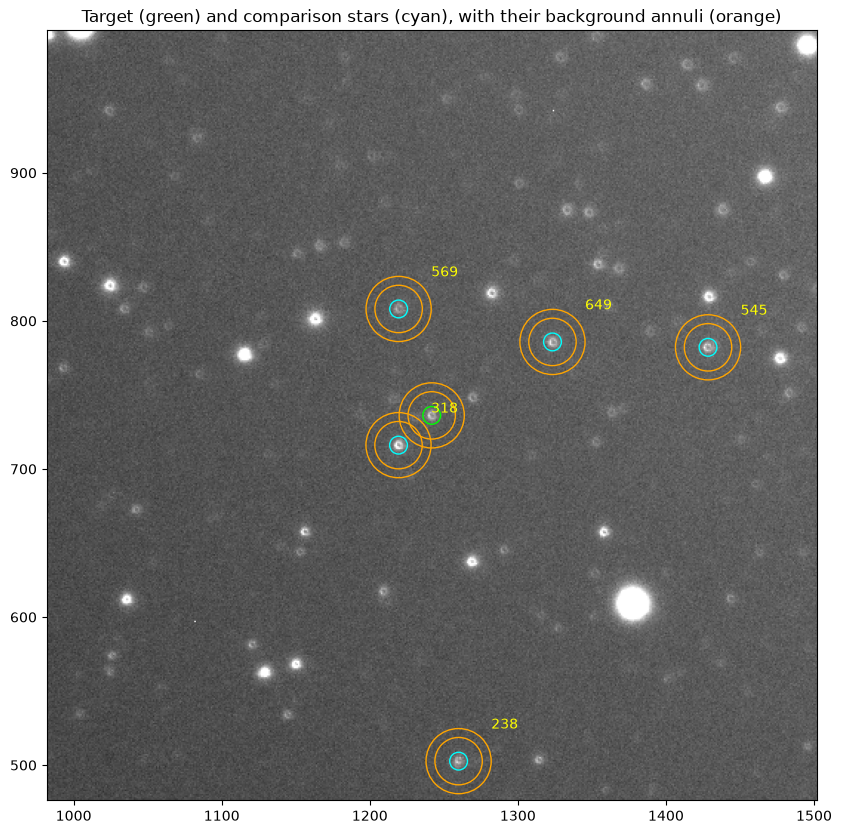

In [ ]:
# Show the target and the chosen comparison stars with their apertures and annuli
plt.figure(figsize=(10, 10))
plt.imshow(science_image, cmap="gray", vmin=vmin, vmax=vmax, origin="lower")

for k in range(len(COMP_INDICES)):
    CircularAperture((comp_x[k], comp_y[k]), r=APERTURE_RADIUS).plot(color="cyan")
    CircularAnnulus((comp_x[k], comp_y[k]), r_in=ANNULUS_IN, r_out=ANNULUS_OUT).plot(color="orange")
    plt.text(comp_x[k] + ANNULUS_OUT, comp_y[k] + ANNULUS_OUT, str(COMP_INDICES[k]),
             color="yellow", fontsize=10, clip_on=True)

aperture.plot(color="lime")      # target aperture (section 7)
annulus.plot(color="orange")     # target annulus

plt.xlim(x_target - ZOOM_HALF_SIZE, x_target + ZOOM_HALF_SIZE)
plt.ylim(y_target - ZOOM_HALF_SIZE, y_target + ZOOM_HALF_SIZE)
plt.title("Target (green) and comparison stars (cyan), with their background annuli (orange)")
plt.show()

### What can go wrong?

**"Target found in the catalog" gives a distance of more than a few arcsec**
The target is not in the downloaded catalog, probably because it is fainter than `CATALOG_MAG_MAX`.
Increase it in section 5 and run the cells again.

**A cyan circle is empty, or next to a star**
The catalog star is too faint to be seen here, or the WCS is slightly off in this area. Do not choose it.

**Two candidates are very close to each other**
Each one would pollute the background annulus of the other. Do not choose them.

**A star is inside the orange annulus of a comparison star (cell 4)**
Replace this comparison star by another one.

**Negative flux, very low SNR, or a flux very different from the others**
The comparison star is badly measured (no star at this position, or a neighbour in the aperture).
Remove it from `COMP_INDICES`.

**Peak above 60000**
The comparison star is saturated: remove it.

**The fluxes do not follow exactly the catalog magnitudes**
This is normal: the TESS filter does not see colours like our camera, and the lens is less sensitive
near the edges of the image (vignetting). Differential photometry compares the *changes* over time,
not the absolute values.

## 9. Write a measurement function

To build a light curve, we must repeat the same measurement for 6 stars (the target and
5 comparison stars) on hundreds of images. Instead of copying the code many times, we put it in a
**function**: a block of code with a name, which takes some inputs and gives back some outputs.

Our function `measure_star` takes an image and an approximate position of a star, and gives back:
- the **flux** of the star,
- its **precise position** (useful to follow the star from one image to the next).

It does exactly what we did by hand in sections 6 and 7 (local background, centroid repeated
several times, aperture photometry), plus some **safety checks**. On real data, a star can be hidden
by a cloud, or the mount can jump: the centroid then gives a wrong position. In these cases the
function does not crash: it returns `nan` ("not a number") as flux, which means "no measurement",
and the position it was given.

Before using it, we **test** it: it must give the same results as our measurements by hand.

In [ ]:
# --- Settings for this section ---
MAX_JUMP = 6    # maximum distance (pixels) between the starting position and the centroid.
                # A larger jump means the centroid went wrong (no star, cloud, neighbour).

def measure_star(img, x_start, y_start):
    """Measure the flux of the star close to (x_start, y_start) in the image img.
    Returns (flux, x, y). If the measurement fails, flux is nan and (x, y) = (x_start, y_start)."""

    # 1. Safety check: the star must not be too close to the edge of the image
    if x_start < 30 or y_start < 30 or x_start > img.shape[1] - 30 or y_start > img.shape[0] - 30:
        return np.nan, x_start, y_start

    # 2. Local background around the star, removed from the image (done once)
    bg = np.median(img[int(y_start) - 30 : int(y_start) + 30, int(x_start) - 30 : int(x_start) + 30])
    img_no_bg = img - bg

    # 3. Centroid, repeated N_ITERATIONS times (section 6)
    x = x_start
    y = y_start
    for k in range(N_ITERATIONS):
        xs, ys = centroid_sources(img_no_bg, x, y, box_size=CENTROID_BOX, centroid_func=centroid_com)

        # Safety check: the centroid must be a real number, and not too far from the start
        ok = (np.isfinite(xs[0]) and np.isfinite(ys[0])
              and abs(xs[0] - x_start) < MAX_JUMP and abs(ys[0] - y_start) < MAX_JUMP)
        if not ok:
            return np.nan, x_start, y_start

        x = xs[0]
        y = ys[0]

    # 4. Aperture photometry (section 7)
    ap = CircularAperture((x, y), r=APERTURE_RADIUS)
    an = CircularAnnulus((x, y), r_in=ANNULUS_IN, r_out=ANNULUS_OUT)
    an_stats = ApertureStats(img, an)
    flux = aperture_photometry(img, ap)["aperture_sum"][0] - an_stats.median * ap.area

    return flux, x, y

In [ ]:
# Test 1: the target. We start from the same position as in section 6 (the WCS prediction),
# so we must get exactly the same result as in section 7.
flux_f, x_f, y_f = measure_star(science_image, x_wcs, y_wcs)
print("Target - by hand :", round(flux_target), " at", round(x_target, 2), round(y_target, 2))
print("Target - function:", round(flux_f), " at", round(x_f, 2), round(y_f, 2))
print()

# Test 2: the comparison stars. We start from their catalog positions, as in section 8.
for k in range(len(COMP_INDICES)):
    i = COMP_INDICES[k]
    flux_f, x_f, y_f = measure_star(science_image, x_cand[i], y_cand[i])
    print("Star", i, "- function: flux =", round(flux_f), " at", round(x_f, 2), round(y_f, 2),
          "   (by hand: at", round(comp_x[k], 2), round(comp_y[k], 2), ")")
print()

# Test 3: the safety check. A position in the corner of the image must give nan, not an error.
flux_f, x_f, y_f = measure_star(science_image, 5, 5)
print("Position in the corner:", flux_f)

Target - by hand : 95912  at 1241.82 736.18
Target - function: 95912  at 1241.82 736.18

Star 318 - function: flux = 144449  at 1219.39 716.09    (by hand: at 1219.39 716.09 )
Star 569 - function: flux = 71022  at 1219.47 808.06    (by hand: at 1219.47 808.06 )
Star 649 - function: flux = 106026  at 1323.37 785.79    (by hand: at 1323.37 785.79 )
Star 545 - function: flux = 110307  at 1428.42 782.14    (by hand: at 1428.42 782.14 )
Star 238 - function: flux = 99318  at 1259.98 502.69    (by hand: at 1259.98 502.69 )

Position in the corner: nan


### What can go wrong?

**The function gives a slightly different result (by about 1%)**
Check that the test starts from the same position as the measurement by hand. If the centroid
starts from another point, it can stop at a position a few tenths of a pixel away, and the flux
changes by about 1%. This is normal, and it shows the precision of the centroid.

**The function gives a very different result**
A setting has been changed between the two measurements (`APERTURE_RADIUS`, `ANNULUS_IN`,
`CENTROID_BOX`...). Run sections 6 to 9 again in order.

**The function returns nan for the target or a comparison star**
The centroid moved more than `MAX_JUMP` pixels from the starting position. Either the starting
position is far from the star (check the WCS, section 5), or `MAX_JUMP` is too small.

**NameError (for example "N_ITERATIONS is not defined")**
The function uses settings from the previous sections: run them first.

**Test 3 gives an error instead of nan**
The safety check at the beginning of the function is missing or wrong.

## 10. Loop over all the images

We now measure the target and the comparison stars on every image of the sequence.
The difficulty is that **the stars do not stay at the same pixels**: the mount drifts slowly,
and sometimes it slips or jumps by tens of pixels. The centroid box (a few pixels) cannot follow
such large movements on its own.

We follow the stars in two steps:
1. **Guide star.** In each image, we look for the brightest star of the whole field (on a reduced
   and blurred image, so that single hot pixels cannot be mistaken for it). Its movement compared
   to the reference image gives the **offset** of the whole field, even after a big jump.
2. **Last known position.** For each star, we remember where it was last measured successfully,
   and we add only the movement of the guide star since then. This corrects small differences
   between stars (a slight rotation of the field, for example), which grow slowly with time.

Each image gives a time (middle of the exposure) and 6 fluxes. A failed measurement gives `nan`.
This cell takes several minutes.

In [ ]:
# --- Settings for this section ---
GUIDE_BLUR = 3       # blur applied to find the guide star (in pixels of the reduced image)
PRINT_EVERY = 25     # print a progress line every N images

def find_guide(img):
    """Find the brightest star of the image. Returns its position (x, y)."""
    small = img[::4, ::4].astype(float)               # keep 1 pixel out of 4: much faster
    blurred = gaussian_filter(small, GUIDE_BLUR)      # blur: hot pixels fade, big stars stay bright
    iy, ix = np.unravel_index(np.argmax(blurred), blurred.shape)   # brightest point (row, column)
    x0 = ix * 4                                       # back to the scale of the full image
    y0 = iy * 4
    bg = np.median(img[max(y0 - 50, 0) : y0 + 50, max(x0 - 50, 0) : x0 + 50])
    xg, yg = centroid_sources(img - bg, x0, y0, box_size=61, centroid_func=centroid_com)
    return xg[0], yg[0]

# Reference positions of the stars in the reference image: target first, then comparison stars
x_ref = [x_target] + comp_x
y_ref = [y_target] + comp_y
n_stars = len(x_ref)

# Position of the guide star in the reference image
x_guide_ref, y_guide_ref = find_guide(science_image)
print("Guide star in the reference image:", round(x_guide_ref, 1), round(y_guide_ref, 1))

# Last successful position of each star, and offset of the guide star at that moment
x_last = list(x_ref)          # list(...) makes a copy, so that x_ref is never modified
y_last = list(y_ref)
dx_last = [0] * n_stars       # a list of n_stars zeros
dy_last = [0] * n_stars

times = []
all_fluxes = []
offsets_x = []
offsets_y = []

for n in range(len(files)):
    data = fits.getdata(files[n], ext=1)
    hdr = fits.getheader(files[n], ext=1)
    if COLOUR_CAMERA:
        data = data[0::2, 1::2]       # same green sub-grid as in section 3

    # Time of the middle of the exposure, in days (Julian Date)
    t = Time(hdr["DATE-OBS"]) + hdr["EXPTIME"] / 2 * u.s
    times.append(t.jd)

    # 1. Offset of the field compared to the reference image
    x_guide, y_guide = find_guide(data)
    dx = x_guide - x_guide_ref
    dy = y_guide - y_guide_ref
    offsets_x.append(dx)
    offsets_y.append(dy)

    # 2. Measure each star, starting from its last known position + movement of the guide since then
    fluxes = []
    for k in range(n_stars):
        x_pred = x_last[k] + (dx - dx_last[k])
        y_pred = y_last[k] + (dy - dy_last[k])
        flux, xk, yk = measure_star(data, x_pred, y_pred)

        if np.isfinite(flux):         # update the memory only if the measurement worked
            x_last[k] = xk
            y_last[k] = yk
            dx_last[k] = dx
            dy_last[k] = dy

        fluxes.append(flux)

    all_fluxes.append(fluxes)

    if n % PRINT_EVERY == 0:
        print("Image", n, "/", len(files), " offset:", round(dx, 1), round(dy, 1), " fluxes:", np.round(fluxes))

print("Done.")

Guide star in the reference image: 570.4 980.0
Image 0 / 476  offset: 0.0 0.0  fluxes: [ 95913. 144451.  71027. 106028. 110307.  99319.]
Image 25 / 476  offset: -185.5 -23.9  fluxes: [ 86680. 145968.  67646. 100274. 113665.  97982.]
Image 50 / 476  offset: -178.8 -36.5  fluxes: [ 84901. 142430.  68314. 107328. 116715.  95830.]
Image 75 / 476  offset: -172.0 -47.7  fluxes: [ 77751. 147234.  69339. 106827. 108058.  98260.]
Image 100 / 476  offset: -164.3 -59.4  fluxes: [ 77853. 144701.  68962. 109229. 116843.  93362.]
Image 125 / 476  offset: -157.1 -67.5  fluxes: [ 78160. 139581.  63859. 103421. 111043.  96084.]
Image 150 / 476  offset: -148.5 -76.0  fluxes: [ 74800. 145440.  67312. 108075. 110407.  96951.]
Image 175 / 476  offset: -139.6 -84.3  fluxes: [ 78980. 144011.  69453. 106441. 111452.  98558.]
Image 200 / 476  offset: -129.1 -93.7  fluxes: [ 84963. 146690.  68057. 104492. 110940.  89675.]
Image 225 / 476  offset: -118.6 -100.2  fluxes: [102111. 139662.  65190. 103708. 116549.  

Images: 476    Images with at least one failed measurement: 0


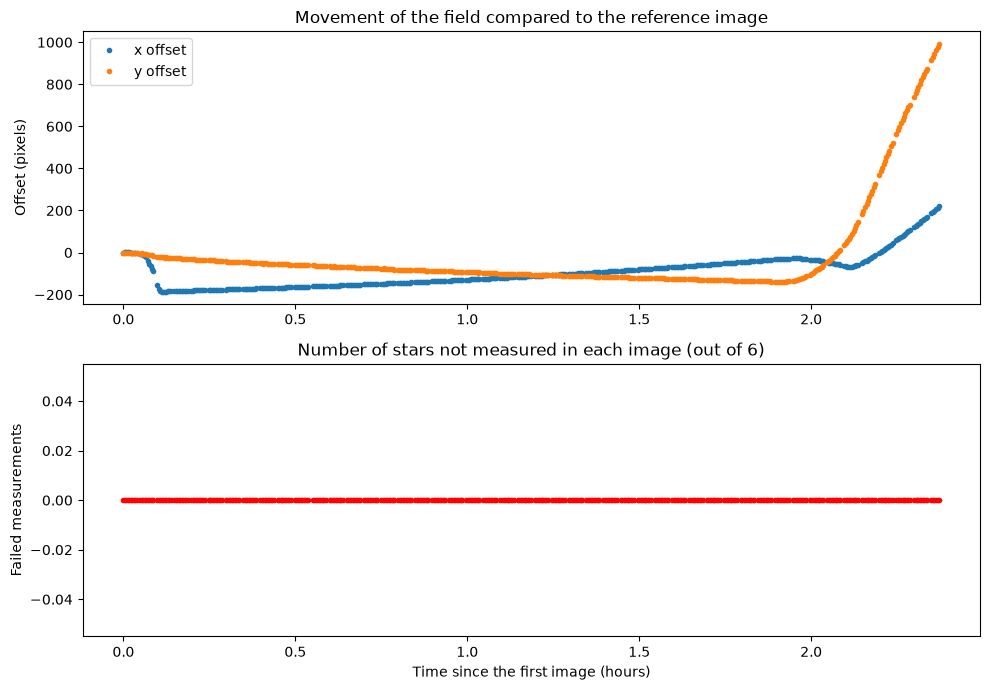

In [ ]:
# Convert the lists into numpy arrays: one line per image, one column per star
times_np = np.array(times)
fluxes_np = np.array(all_fluxes)
hours = (times_np - times_np[0]) * 24          # time since the first image, in hours

# Number of failed measurements (nan) in each image
n_failed = np.sum(np.isnan(fluxes_np), axis=1)
print("Images:", len(times_np), "   Images with at least one failed measurement:", np.sum(n_failed > 0))

plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.plot(hours, offsets_x, ".", label="x offset")
plt.plot(hours, offsets_y, ".", label="y offset")
plt.ylabel("Offset (pixels)")
plt.title("Movement of the field compared to the reference image")
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(hours, n_failed, ".", color="red")
plt.xlabel("Time since the first image (hours)")
plt.ylabel("Failed measurements")
plt.title("Number of stars not measured in each image (out of " + str(n_stars) + ")")

plt.tight_layout()
plt.show()

### What can go wrong?

**How to read the offset plot**
A slow, smooth drift is normal. Steps of a few pixels per image mean the mount is slipping;
a sudden jump means the mount moved (correction of pointing, wind...). Thanks to the guide star,
the measurements should continue normally after a jump.

**The offset jumps between very different values (hundreds of pixels), back and forth**
Two stars of similar brightness compete to be "the brightest": the guide star changes from one
image to the next. Try a different `GUIDE_BLUR`, or use another reference image.

**Many failed measurements over a long period**
The predicted positions are wrong by more than `MAX_JUMP` pixels. Look at the offset plot at the
same time: a very fast drift or jump can explain it. Increasing `MAX_JUMP` slightly can help.

**All stars fail at the same time, for a few images**
A cloud, or stars stretched by a movement of the mount. These images will be removed in section 11.

**An error stops the loop**
Note the image number printed last, open this image (section 2) and look at it.

## 11. Plot the light curve and check its quality

For each image, we compare the flux of the target with the total flux of the comparison stars,
and we express it as a difference of magnitude:

$$\Delta m = -2.5\,\log_{10}\left(\frac{F_\text{target}}{\sum_k F_{\text{comp},k}}\right)$$

Magnitudes work "upside down": a smaller magnitude means a brighter star, so the vertical axis is inverted.
We subtract the median so that the curve is centred on 0.

**The control curve.** We do the same calculation between two comparison stars. Neither of them is
variable, so this curve should be flat. Its scatter tells us the precision of our measurements, and
the images where it jumps are bad images (clouds, stretched stars...). We remove these images from
the light curve: here, the points more than 3 times the scatter away from 0.

For DY Peg, we expect a regular pulsation of about 0.6 magnitude with a period of 1.75 hours:
a fast increase of brightness, then a slower decrease.

Valid points: 473 out of 476
Images removed by the control curve: 3
Scatter of the control curve: 0.043 mag


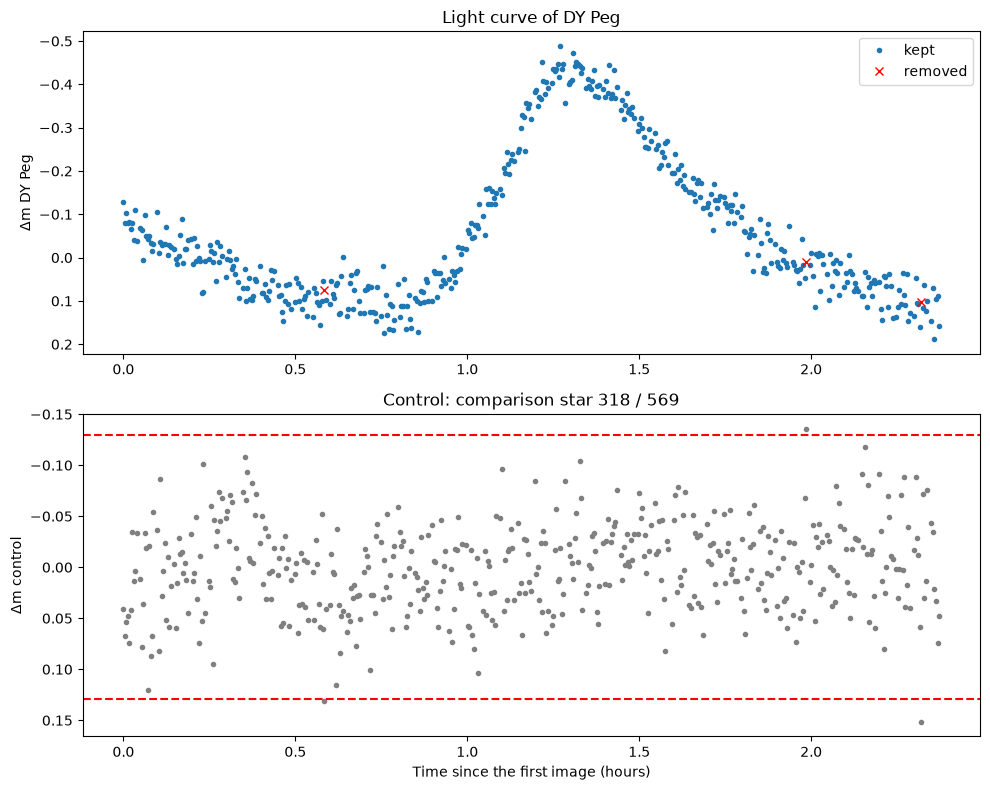

In [ ]:
# --- Settings for this section ---
CLIP_LEVEL = 3   # images where the control curve is more than CLIP_LEVEL x its scatter away from 0 are removed

# Light curve: target compared with the sum of the comparison stars.
# If one comparison star failed (nan), the sum is nan and the image is skipped.
flux_target_all = fluxes_np[:, 0]
flux_comp_sum = np.sum(fluxes_np[:, 1:], axis=1)
delta_m = -2.5 * np.log10(flux_target_all / flux_comp_sum)
delta_m = delta_m - np.nanmedian(delta_m)

# Control curve: first comparison star compared with the second one
control = -2.5 * np.log10(fluxes_np[:, 1] / fluxes_np[:, 2])
control = control - np.nanmedian(control)
control_std = np.nanstd(control)

# Bad images: the control curve is too far from 0
bad = np.abs(control) > CLIP_LEVEL * control_std
delta_m_clean = delta_m.copy()
delta_m_clean[bad] = np.nan

print("Valid points:", np.sum(np.isfinite(delta_m_clean)), "out of", len(delta_m))
print("Images removed by the control curve:", np.sum(bad))
print("Scatter of the control curve:", round(control_std, 3), "mag")

plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(hours, delta_m_clean, ".", label="kept")
plt.plot(hours[bad], delta_m[bad], "x", color="red", label="removed")
plt.gca().invert_yaxis()
plt.ylabel("Δm " + TARGET_NAME)
plt.title("Light curve of " + TARGET_NAME)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(hours, control, ".", color="gray")
plt.axhline(CLIP_LEVEL * control_std, color="red", linestyle="--")
plt.axhline(-CLIP_LEVEL * control_std, color="red", linestyle="--")
plt.gca().invert_yaxis()
plt.xlabel("Time since the first image (hours)")
plt.ylabel("Δm control")
plt.title("Control: comparison star " + str(COMP_INDICES[0]) + " / " + str(COMP_INDICES[1]))

plt.tight_layout()
plt.show()

### What can go wrong?

**The control curve is not flat (slow trend or bump)**
One of the two comparison stars is variable, or badly measured (neighbour in its annulus).
Try another pair of comparison stars, or remove the suspicious one from `COMP_INDICES` (section 8)
and run sections 8 to 11 again.

**The scatter of the control curve is large (more than ~0.05 mag)**
Bad conditions (clouds, mount problems), or an aperture radius that is too small or too large.
You can try another `APERTURE_RADIUS` (section 7) and run the loop again: keep the radius that
gives the smallest scatter.

**Gaps in the light curve**
Many failed measurements at that time: look at the plots of section 10.

**Many points removed**
Check `CLIP_LEVEL`: with 3, only clearly bad images should be removed.

**The light curve looks flat**
The target may not vary during the observation, or its variation is smaller than the scatter
of the control curve.

## 12. Save the results

The loop takes several minutes, so we save the results in a CSV file. It can be opened in a
spreadsheet, or loaded again in Python with `Table.read("light_curve.csv")`, without running the loop again.

In [ ]:
results = Table()
results["time_jd"] = times_np                  # middle of the exposure, Julian Date (UTC)
results["hours"] = hours                       # time since the first image, in hours
results["flux_target"] = fluxes_np[:, 0]
for k in range(len(COMP_INDICES)):
    results["flux_comp_" + str(COMP_INDICES[k])] = fluxes_np[:, k + 1]
results["delta_m"] = delta_m
results["control"] = control
results["bad_image"] = bad                     # True if the image was removed in section 11

results.write("light_curve.csv", overwrite=True)
print("Saved:", len(results), "lines in light_curve.csv")

Saved: 476 lines in light_curve.csv
